In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install mediapipe==0.10.13 -q
print('All dependencies installed!')

All dependencies installed!


In [3]:
import os
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical


DATA_PATH = "/content/drive/Shareddrives/PRJ303_Dataset/dataset"

X = []
y = []

labels = os.listdir(DATA_PATH)

for label in labels:
    folder = os.path.join(DATA_PATH, label)
    for file in os.listdir(folder):
        path = os.path.join(folder, file)
        data = np.load(path)
        X.append(data)
        y.append(label)

X = np.array(X)
y = np.array(y)

le = LabelEncoder()
y = le.fit_transform(y)
y = to_categorical(y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)


In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential([
    LSTM(128, return_sequences=True, input_shape=(X.shape[1], X.shape[2])),
    Dropout(0.3),
    LSTM(128),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(y.shape[1], activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history=model.fit(X_train, y_train, epochs=30, batch_size=32, validation_data=(X_test, y_test))

model.save('/content/drive/Shareddrives/PRJ303_Dataset/lstm_model.keras')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 9s 189ms/step - accuracy: 0.3250 - loss: 1.7312 - val_accuracy: 0.4143 - val_loss: 1.4755
Epoch 2/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 197ms/step - accuracy: 0.4857 - loss: 1.3570 - val_accuracy: 0.4000 - val_loss: 1.4991
Epoch 3/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 216ms/step - accuracy: 0.5179 - loss: 1.2444 - val_accuracy: 0.6929 - val_loss: 1.0372
Epoch 4/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 150ms/step - accuracy: 0.6339 - loss: 0.9621 - val_accuracy: 0.6643 - val_loss: 0.9701
Epoch 5/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 156ms/step - accuracy: 0.7696 - loss: 0.6799 - val_accuracy: 0.8071 - val_loss: 0.6031
Epoch 6/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 158ms/step - accuracy: 0.8000 - loss: 0.6010 - val_accuracy: 0.7571 - val_loss: 0.6133
Epoch 7/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 257ms/step - accuracy: 0.7018 - loss: 0.8661 - val_accuracy: 0.6929 - val_loss: 0.7692
Epoch 8/30
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 153ms/step - accuracy: 0.7982 - loss: 0.6014 - val_accuracy: 0.

In [5]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8357 - loss: 0.5897
Test Loss: 0.5897115468978882
Test Accuracy: 0.8357142806053162


In [17]:
import joblib

joblib.dump(le, save_path + "label_encoder.pkl")

['/content/drive/Shareddrives/PRJ303_Dataset/label_encoder.pkl']

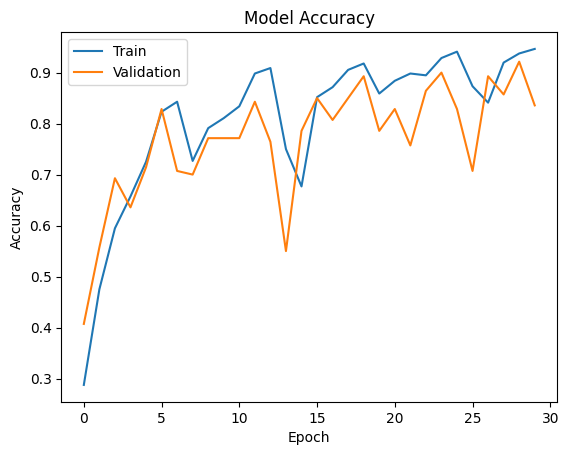

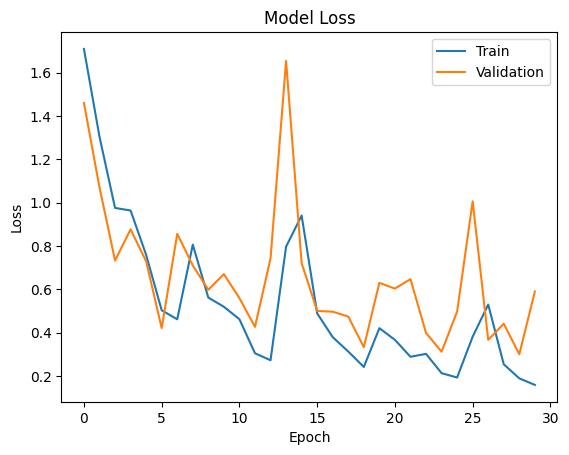

In [6]:
import matplotlib.pyplot as plt

# Plot Accuracy
plt.figure()
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])
plt.show()

# Plot Loss
plt.figure()
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'])
plt.show()

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 186ms/step


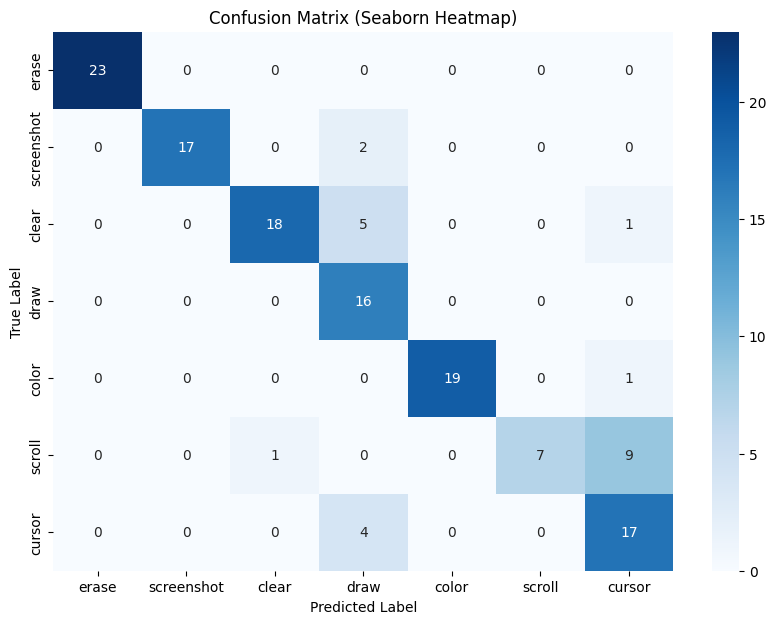

In [7]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Predict
y_pred = model.predict(X_test)

# Convert one-hot → labels
y_pred_labels = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred_labels)

# Plot using seaborn
plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,          # show numbers
    fmt='d',             # integer format
    cmap='Blues',        # color theme
    xticklabels=labels,  # predicted classes
    yticklabels=labels   # actual classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (Seaborn Heatmap)")
plt.show()

In [14]:
from google.colab import drive
from google.colab.patches import cv2_imshow
from IPython.display import display, Javascript
from base64 import b64decode
import cv2
import numpy as np
import mediapipe as mp
import joblib
from collections import deque

print("Imports done!")

Imports done!


In [20]:
from tensorflow.keras.models import load_model
import joblib

save_path = '/content/drive/Shareddrives/PRJ303_Dataset/'

model = load_model(save_path + 'lstm_model.keras')
le_rt = joblib.load(save_path + 'label_encoder.pkl')

print("Model loaded!")
print("Classes:", le_rt.classes_)

Model loaded!
Classes: ['clear' 'color' 'cursor' 'draw' 'erase' 'screenshot' 'scroll']


In [21]:
import mediapipe as mp
import numpy as np
import cv2

mp_hands = mp.solutions.hands
mp_draw  = mp.solutions.drawing_utils

def extract_features_two_hands(results):
    left_hand  = np.zeros(63)
    right_hand = np.zeros(63)

    if results.multi_hand_landmarks and results.multi_handedness:
        for hand_landmarks, handedness in zip(
            results.multi_hand_landmarks, results.multi_handedness
        ):
            hand_features = []
            for lm in hand_landmarks.landmark:
                hand_features.extend([lm.x, lm.y, lm.z])

            if handedness.classification[0].label == 'Left':
                right_hand = np.array(hand_features)
            else:
                left_hand = np.array(hand_features)

    return np.concatenate([left_hand, right_hand])  # 126

In [22]:
from IPython.display import display, Javascript
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
    async function takePhoto(quality) {
        const div = document.createElement('div');
        const capture = document.createElement('button');
        capture.textContent = 'Capture Frame';
        div.appendChild(capture);

        const video = document.createElement('video');
        video.style.display = 'block';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        document.body.appendChild(div);
        div.appendChild(video);
        video.srcObject = stream;
        await video.play();

        await new Promise((resolve) => capture.onclick = resolve);

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);

        stream.getVideoTracks()[0].stop();
        div.remove();
        return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
    display(js)

    from google.colab.output import eval_js
    data = eval_js(f'takePhoto({quality})')
    binary = b64decode(data.split(',')[1])

    with open(filename, 'wb') as f:
        f.write(binary)

    return filename

In [29]:
SEQUENCE_LENGTH = 30
sequence = []

print("Capture 30 frames for gesture...")

for i in range(SEQUENCE_LENGTH):
    filename = take_photo(f'frame_{i}.jpg')

    frame = cv2.imread(filename)
    frame = cv2.flip(frame, 1)
    rgb   = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    with mp_hands.Hands(
        max_num_hands=2,
        min_detection_confidence=0.7,
        min_tracking_confidence=0.7
    ) as hands:

        results = hands.process(rgb)

        if results.multi_hand_landmarks:
            keypoints = extract_features_two_hands(results)
        else:
            keypoints = np.zeros(126)

        sequence.append(keypoints)

# Convert to correct shape
sequence = np.array(sequence)              # (30,126)
sequence = np.expand_dims(sequence, axis=0)  # (1,30,126)

# Predict
res = model.predict(sequence)[0]

predicted_class = np.argmax(res)
gesture_name = le_rt.inverse_transform([predicted_class])[0]

print("\nAll class probabilities:")
for name, prob in zip(le_rt.classes_, res):
    print(f"{name}: {prob*100:.2f}%")

print(f"\n✅ Predicted Gesture: {gesture_name}")

Capture 30 frames for gesture...


<IPython.core.display.Javascript object>

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step

All class probabilities:
clear: 10.32%
color: 12.91%
cursor: 16.03%
draw: 16.47%
erase: 12.87%
screenshot: 15.41%
scroll: 15.98%

✅ Predicted Gesture: draw


/usr/local/lib/python3.12/dist-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '
